# QFF 2026 Phase 1 — PS-O2 Portfolio Optimization

End-to-end, reproducible benchmark comparing Processor A and Processor B on the four-asset PS-O2 instance. Inputs are transcribed from the QFF Phase 1 Master Guide, page 4.

The prescribed repository layout does not include a standalone `main.py` or `src/qaoa.py`: the driver is embedded in this notebook and p=1 QAOA routines are included in `src/problem.py`.

## 1. Configure the experiment

`Q` is participant-selected because the Master Guide does not prescribe a numeric `q`. `1.0` is an example, not an official value. The current configuration runs both ideal and synthetic-noise cases.

In [1]:
Q = 1.0  # provisional participant-selected example; pending organizer confirmation
PENALTY_A = 0.02  # participant-selected; not organizer-fixed
ROBUSTNESS_SEEDS = [7, 21, 42, 84, 126, 168, 210, 252, 294, 336]  # 10-seed supplementary robustness; baseline seed remains 42


## 2. Imports and reusable functions

Run from the repository root. The implementation uses the required `src/` modules and writes only to `results/tables/`, `results/figures/`, and `report.md`.

In [2]:
#!/usr/bin/env python3
"""Run the QFF Phase 1 Master Guide PS-O2 A/B benchmark."""
from __future__ import annotations
import csv, json
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
from src.problem import load_instance, enumerate_solutions, qubo_matrix, validate_qubo_conversion
from src.processors import load_processor, build_synthetic_noise_model
from src.problem import optimize_qaoa, sample_processor, prepare_cost_model, base_cost, full_cost, bitvector_from_int, utility

ROOT=Path.cwd(); DATA=ROOT/"data/processed/portfolio_instance.json"; PROC=ROOT/"processors"; RESULTS=ROOT/"results"
if not DATA.is_file(): raise RuntimeError("Run this notebook from the repository root.")

def write_json(path,data):
    path.parent.mkdir(parents=True,exist_ok=True)
    with path.open("w",encoding="utf-8") as f: json.dump(data,f,indent=2,allow_nan=False)

def write_csv(path,rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    if not rows: return
    fields=list(rows[0].keys())
    with path.open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=fields,extrasaction="ignore",lineterminator="\n"); w.writeheader()
        for row in rows: w.writerow({k:(json.dumps(v) if isinstance(v,(dict,list)) else v) for k,v in row.items() if k in fields})

def strip_circuit(row):
    row=dict(row); row.pop("transpiled_circuit",None); row.pop("counts",None); row.pop("sampled_distribution",None)
    return row



## 3. Run the full benchmark

This cell runs the exact classical enumeration, p=1 QAOA parameter optimization, and Processor A/B ideal and noisy Aer simulations using the baseline settings: basis `{rz, sx, x, cx}`, optimization level 1, SABRE layout/routing, seed 42, and 4096 shots.

In [3]:
def main(q_value: float = Q, penalty_a: float = PENALTY_A, run_noisy: bool = True):
    RESULTS.mkdir(exist_ok=True); (RESULTS/"figures").mkdir(parents=True,exist_ok=True); (RESULTS/"tables").mkdir(parents=True,exist_ok=True)
    instance=load_instance(DATA)
    q=float(q_value); penalty_a=float(penalty_a)
    if not np.isfinite(q) or q <= 0:
        raise ValueError("Q must be finite and positive; the Master Guide does not prescribe its value.")
    if not np.isfinite(penalty_a) or penalty_a <= 0:
        raise ValueError("PENALTY_A must be finite and positive; the Master Guide does not prescribe its value.")
    instance["q"] = q
    instance["q_selection_status"] = "Provisional participant-selected q pending organizer confirmation; Master Guide does not prescribe a numerical q."
    instance["cardinality_penalty_A"] = penalty_a
    instance["penalty_source_note"] = "A=0.02 is a participant-selected penalty, not an organizer-fixed value. For provisional q=1.0, exact enumeration gives a strict-feasibility threshold A>0.01 for this instance under the squared-cardinality penalty. Recalculate the threshold if q changes."
    instance["penalty_status"] = "PROVISIONAL_PENDING_ORGANIZER_CONFIRMATION"
    instance["source_status"] = "MASTER_GUIDE_INPUTS_WITH_PROVISIONAL_Q_AND_PENALTY_PENDING_ORGANIZER_CONFIRMATION"
    instance["decision_variable_interpretation"] = "Binary asset-selection variables x_i in {0,1}; exactly k=2 assets are selected."
    write_json(DATA,instance)
    instance=load_instance(DATA); validate_qubo_conversion(instance)
    a=float(instance["cardinality_penalty_A"]); q=float(instance["q"])
    print(f"PS-O2 Master Guide inputs loaded: mu={instance['expected_returns']}, k=2, q={q}, A={a}")
    print("NOTE: q is participant-selected because the Master Guide does not assign a value. The report will disclose this.")
    solutions=enumerate_solutions(instance,a); feasible=[s for s in solutions if s["feasible"]]
    optimum=max(feasible,key=lambda s:s["utility"])
    Q,c=qubo_matrix(instance)
    with (RESULTS/"tables/qubo_matrix.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.writer(f,lineterminator="\n"); w.writerow(["asset"]+instance["assets"]);
        for i,name in enumerate(instance["assets"]): w.writerow([name]+[float(v) for v in Q[i]])
    write_json(RESULTS/"tables/qubo_matrix.json",{"convention":"C(x)=x.T @ Q @ x + constant","Q":Q.tolist(),"constant":c,"q":q,"penalty_A":a})
    params=optimize_qaoa(instance,restarts=int(instance.get("classical_restarts",6)),maxiter=int(instance.get("optimizer_maxiter",300)),seed=42)
    processors=[load_processor(PROC/"processor_A.json"),load_processor(PROC/"processor_B.json")]
    noise=build_synthetic_noise_model(); rows=[]; full=[]
    for processor in processors:
        for mode in (["ideal","noisy"] if run_noisy else ["ideal"]):
            print(f"Running {processor['name']} / {mode} with SABRE, level 1, seed 42, 4096 shots...")
            row=sample_processor(instance,params,processor,mode=mode,noise_model=noise if mode=="noisy" else None,shots=4096)
            full.append(row); rows.append(strip_circuit(row))
    write_json(RESULTS/"tables"/"classical_solutions.json",{"solutions":solutions,"exact_optimum":optimum})
    write_json(RESULTS/"tables"/"qaoa_parameters.json",{"gamma":params["gamma"],"beta":params["beta"],"best_restart":params["best_restart"],"best_expected_scaled_cost":params["best_expected_scaled_cost"],"restarts":params["restarts"],"q":q,"penalty_A":a})
    output_rows=[]
    for row in rows:
        output_rows.append({k:v for k,v in row.items() if k not in ("counts",)})
    write_csv(RESULTS/"tables/processor_comparison.csv",output_rows)
    metadata={"problem_code":"PS-O2","instance_source":"QFF_Phase_1_Master_Guide.pdf page 4 inputs","expected_returns":instance["expected_returns"],"risk_matrix":instance["risk_matrix"],"q":q,"q_status":instance.get("q_selection_status","participant-selected; q is not stated in Master Guide"),"cardinality_k":2,"cardinality_penalty_A":a,"penalty_source_note":instance.get("penalty_source_note"),"shots":4096,"optimization_level":1,"layout_method":"sabre","routing_method":"sabre","seed_transpiler":42,"seed_simulator":42,"noise_model":{"one_qubit_depolarizing":0.001,"cx_depolarizing":0.005,"readout_bitflip":0.01},"noise_note":"Master Guide synthetic noise model; ideal and noisy results separated","qaoa_depth_p":1,"optimizer_restarts":int(instance.get("classical_restarts",20)),"optimizer_maxiter":int(instance.get("optimizer_maxiter",500))}
    write_json(RESULTS/"tables"/"run_metadata.json",metadata)
    # Plots: exact objective of all feasible portfolios.
    labels=[" + ".join(s["selected_assets"]) for s in sorted(feasible,key=lambda z:z["utility"],reverse=True)]
    values=[s["utility"] for s in sorted(feasible,key=lambda z:z["utility"],reverse=True)]
    fig,ax=plt.subplots(figsize=(10,5)); ax.bar(range(len(values)),values); ax.set_xticks(range(len(values)),labels,rotation=35,ha="right"); ax.set_ylabel("Unpenalized objective q·return − risk"); ax.set_title("Exact classical feasible portfolios"); ax.grid(axis="y",alpha=.25); fig.tight_layout(); fig.savefig(RESULTS/"figures/classical_portfolio_objectives.png",dpi=180); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    for ax,processor in zip(axes,processors):
        g=nx.Graph(); g.add_nodes_from(range(processor["num_qubits"])); g.add_edges_from(processor["coupling_edges_undirected"]); pos=nx.spring_layout(g,seed=42); nx.draw_networkx(g,pos,ax=ax,node_size=500,font_size=9); ax.set_title(f"{processor['name']} ({processor['num_qubits']} qubits)"); ax.axis("off")
    fig.tight_layout(); fig.savefig(RESULTS/"figures/processor_topologies.png",dpi=180); plt.close(fig)
    for row in full:
        dist=sorted(row["sampled_distribution"],key=lambda z:z["probability"],reverse=True)[:12]; fig,ax=plt.subplots(figsize=(8,4)); ax.bar([x["bitstring"] for x in dist],[x["probability"] for x in dist]); ax.set_title(f"{row['processor']} — {row['mode']} outcome distribution"); ax.set_xlabel("Bitstring (asset 4 … asset 1)"); ax.set_ylabel("Probability"); fig.tight_layout(); fig.savefig(RESULTS/f"figures/qaoa_distribution_{row['processor'].lower().replace(' ','_')}_{row['mode']}.png",dpi=180); plt.close(fig)
    # Report includes source and configuration qualifications.
    lines=["# QFF 2026 Phase 1 — PS-O2 Portfolio Optimization","","## Benchmark provenance","",f"- Inputs: QFF Phase 1 Master Guide, page 4.",f"- Returns μ: `{instance['expected_returns']}`",f"- Risk matrix minimum eigenvalue: `{instance['risk_matrix_min_eigenvalue']:.8f}`",f"- q: `{q}` — participant-selected because the Master Guide's PS-O2 section does not prescribe a numeric value.",f"- Cardinality: exactly 2 assets.",f"- Penalty A: `{a}` — provisional participant-selected assumption pending organizer confirmation; the Master Guide PS-O2 entry does not specify A.","- Formulation: minimize `x.T @ Sigma @ x - q * mu.T @ x + A * (sum(x)-2)^2`.","- Reported economic objective: `q * mu.T @ x - x.T @ Sigma @ x`, only on feasible portfolios.","","## Exact classical reference","",f"- Optimal portfolio: {', '.join(optimum['selected_assets'])}",f"- Bitstring (asset 4 … asset 1): `{optimum['bitstring']}`",f"- Best feasible unpenalized objective: `{optimum['utility']:.10f}`","","## Controlled Processor A/B results","","| Processor | Mode | Qubits | Depth | CX | SWAP diagnostic | Valid probability | Optimal probability | Mean utility (all samples) | Mean utility (valid only) | Best sampled valid objective | Best-sample ratio | Gap |","|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for r in rows:
        ratio="N/A" if r.get("best_sampled_objective_ratio") is None else f"{r['best_sampled_objective_ratio']:.6f}"
        best="N/A" if r.get("best_sampled_valid_utility") is None else f"{r['best_sampled_valid_utility']:.8f}"
        gap="N/A" if r.get("optimality_gap") is None else f"{r['optimality_gap']:.8f}"
        mean_all=f"{r['sampled_expected_utility_all_outcomes']:.8f}"
        mean_valid="N/A" if r.get("sampled_expected_utility_given_valid") is None else f"{r['sampled_expected_utility_given_valid']:.8f}"
        lines.append(f"| {r['processor']} | {r['mode']} | {r['processor_qubits']} | {r['depth']} | {r['cx_count']} | {r['swap_count_diagnostic']} | {r['valid_portfolio_probability']:.4f} | {r['optimal_portfolio_probability']:.4f} | {mean_all} | {mean_valid} | {best} | {ratio} | {gap} |")

    lines += ["","## Compilation protocol","","- QAOA p=1; same logical circuit and optimized angles for both processors.","- Basis gates `{rz, sx, x, cx}`; optimization level 1; SABRE layout/routing; transpiler seed 42; 4096 shots.","- Noise model: one-qubit depolarizing 0.001; CX depolarizing 0.005. The guide only gives a 1% readout error rate, not a confusion matrix; this implementation models it as symmetric 1% bit-flip and records that assumption. Ideal and noisy runs are reported separately.","- SWAP count comes from a separate diagnostic transpilation with SWAP retained; it is not the native-basis circuit's literal SWAP count.","","## Interpretation and limitations","","- Four assets yield only 16 bitstrings and can be solved exactly classically; no quantum advantage is claimed.\n- The best-sampled objective ratio equals 1 when at least one sample reaches the exact optimum; interpret it alongside optimal-portfolio probability, not as an average-quality or success-probability metric.","- The numeric q is not specified in the Master Guide and was selected provisionally for this run; obtain organizer confirmation before treating it as official.",
"- Penalty A is a provisional participant-selected implementation choice; obtain organizer confirmation before treating it as official.",
"- Decision variables are interpreted as binary asset-selection indicators; confirm this interpretation if continuous weights were intended.","- Coupling graphs are reference architectures. The included A/B runs use the documented reference edges; any participant-designed topology must be reported separately.","- The synthetic noise results are Aer simulation measurements, not hardware measurements.",
"- Generative AI assisted code drafting/review and documentation organization; the participant remains responsible for checking every assumption and result, subject to the event AI-use policy.","","## Reproducibility","","Run every code cell in `main.ipynb` from the repository root after setting `Q` in the configuration cell. Tables are regenerated under `results/tables/`, figures under `results/figures/`, and the report at `report.md`.",""]
    (ROOT/"report.md").write_text("\n".join(lines),encoding="utf-8")
    print("\nBenchmark complete. Best feasible classical portfolio:", ", ".join(optimum["selected_assets"]))
    print("Results:",RESULTS)
    print("IMPORTANT: q was selected by the participant because the Master Guide does not specify it. Read report.md before treating values as official.")

main(q_value=Q, penalty_a=PENALTY_A, run_noisy=True)


PS-O2 Master Guide inputs loaded: mu=[0.12, 0.18, 0.1, 0.22], k=2, q=1.0, A=0.02
NOTE: q is participant-selected because the Master Guide does not assign a value. The report will disclose this.


Running Processor A / ideal with SABRE, level 1, seed 42, 4096 shots...
Running Processor A / noisy with SABRE, level 1, seed 42, 4096 shots...
Running Processor B / ideal with SABRE, level 1, seed 42, 4096 shots...
Running Processor B / noisy with SABRE, level 1, seed 42, 4096 shots...



Benchmark complete. Best feasible classical portfolio: Asset_1, Asset_4
Results: /home/ashwathraj/Acadimics/3.Semister3/Hackthons/Certificate/QFF IBM  singularity/Project/qff-o2-portfolio-phase1/results
IMPORTANT: q was selected by the participant because the Master Guide does not specify it. Read report.md before treating values as official.


## 4. Inspect generated metrics and figures

The four-asset instance has only 16 bitstrings and can be solved exactly classically; this is a topology, routing, resource-metric, and synthetic-noise comparison, not a quantum-advantage claim.

## 4. Supplementary experiments: topology, robustness, and parameter sensitivity

The preceding A/B × ideal/noisy table remains the required Master Guide reference baseline. This section adds separately labelled participant-designed topologies and supplementary analyses; it does not overwrite or replace the required baseline. The current Q and penalty are provisional until the organizers clarify them.

The alternative Processor A graph is a 5-node, 4-edge linear chain. The alternative Processor B graph is a connected 9-node, 12-edge ring with three chords. Structural metrics are exported so the topology rationale is evidence-based rather than assumed.


In [4]:
# QFF-SUPPLEMENTARY-TOPOLOGY-ROBUSTNESS — separate from the required reference baseline
from statistics import mean, stdev

from src.processors import ALTERNATIVE_TOPOLOGIES, make_topology_variant, topology_metrics

# Load the current data and the exact same logical QAOA parameters used by the required baseline.
_instance = load_instance(DATA)
_saved_params = json.loads((RESULTS / "tables/qaoa_parameters.json").read_text(encoding="utf-8"))
_params = {
    "gamma": float(_saved_params["gamma"]),
    "beta": float(_saved_params["beta"]),
    "cost_model": prepare_cost_model(_instance),
}
_noise = build_synthetic_noise_model()
_reference_processors = [load_processor(PROC / "processor_A.json"), load_processor(PROC / "processor_B.json")]
_baseline_rows = list(csv.DictReader((RESULTS / "tables/processor_comparison.csv").open(newline="", encoding="utf-8")))
_baseline_lookup = {(row["processor"], row["mode"]): row for row in _baseline_rows}

# The graph alternatives are in-memory variants only. The official reference JSON files stay unchanged.
_variant_processors = []
for _processor in _reference_processors:
    _spec = ALTERNATIVE_TOPOLOGIES[_processor["name"]]
    _variant = make_topology_variant(_processor, _spec["label"], _spec["edges"])
    _variant_processors.append((_processor["name"], _variant, _spec["label"], _spec["rationale"]))

_topology_entries = []
_alt_run_cache = {}

def _number(value, default=None):
    if value is None or value == "" or value == "None":
        return default
    return float(value)

def _topology_row(family, label, role, processor, mode, metrics_row, rationale):
    gm = topology_metrics(processor)
    return {
        "processor_family": family,
        "topology_role": role,
        "topology_label": label,
        "mode": mode,
        "num_qubits": gm["num_qubits"],
        "edge_count": gm["edge_count"],
        "degree_sequence_by_node": gm["degree_sequence_by_node"],
        "minimum_degree": gm["minimum_degree"],
        "maximum_degree": gm["maximum_degree"],
        "degree_mean": gm["degree_mean"],
        "degree_std_population": gm["degree_std_population"],
        "graph_diameter": gm["diameter"],
        "average_shortest_path_length": gm["average_shortest_path_length"],
        "depth": int(float(metrics_row["depth"])),
        "cx_count": int(float(metrics_row["cx_count"])),
        "swap_count_diagnostic": int(float(metrics_row["swap_count_diagnostic"])),
        "valid_portfolio_probability": _number(metrics_row.get("valid_portfolio_probability")),
        "optimal_portfolio_probability": _number(metrics_row.get("optimal_portfolio_probability")),
        "sampled_expected_utility_given_valid": _number(metrics_row.get("sampled_expected_utility_given_valid")),
        "best_sampled_valid_utility": _number(metrics_row.get("best_sampled_valid_utility")),
        "best_sampled_objective_ratio": _number(metrics_row.get("best_sampled_objective_ratio")),
        "optimality_gap": _number(metrics_row.get("optimality_gap")),
        "shots": int(float(metrics_row.get("shots", 4096))),
        "seed_transpiler": int(float(metrics_row.get("seed_transpiler", 42))),
        "seed_simulator": int(float(metrics_row.get("seed_simulator", 42))),
        "rationale": rationale,
    }

for _processor in _reference_processors:
    _family = _processor["name"]
    _gm = topology_metrics(_processor)
    for _mode in ("ideal", "noisy"):
        _row = _baseline_lookup[(_family, _mode)]
        _topology_entries.append(_topology_row(
            _family, "Master Guide reference", "reference_baseline", _processor,
            _mode, _row, "Required baseline; retained unchanged."
        ))

for _family, _variant, _label, _rationale in _variant_processors:
    for _mode in ("ideal", "noisy"):
        print(f"Supplementary topology run: {_variant['name']} / {_mode}, seed 42")
        _sample = sample_processor(
            _instance, _params, _variant, mode=_mode,
            noise_model=_noise if _mode == "noisy" else None,
            shots=4096, seed_simulator=42,
        )
        _alt_run_cache[(_family, _mode)] = _sample
        _topology_entries.append(_topology_row(
            _family, f"Alternative: {_label}", "supplementary_participant_designed",
            _variant, _mode, _sample, _rationale
        ))

write_csv(RESULTS / "tables/topology_experiment.csv", _topology_entries)

# Structural metadata includes the complete edge lists. This makes the experiment fully auditable
# without adding unprescribed processor JSON files to the required repository structure.
_topology_metadata = {
    "status": "SUPPLEMENTARY_EXPERIMENT_NOT_A_REPLACEMENT_FOR_REQUIRED_BASELINE",
    "q": float(_instance["q"]),
    "q_status": _instance.get("q_selection_status"),
    "cardinality_penalty_A": float(_instance["cardinality_penalty_A"]),
    "penalty_status": _instance.get("penalty_status", "PROVISIONAL_PENDING_ORGANIZER_CONFIRMATION"),
    "shared_logical_qaoa_parameters": {"gamma": _params["gamma"], "beta": _params["beta"], "p": 1},
    "transpiler_settings": {"optimization_level": 1, "layout": "sabre", "routing": "sabre", "seed_transpiler": 42, "shots": 4096},
    "noisy_settings": {"one_qubit_depolarizing": 0.001, "cx_depolarizing": 0.005, "symmetric_readout_bitflip": 0.01},
    "topologies": [],
    "note": "All variants have the same qubit budget and the same undirected edge count as their corresponding reference. Compare as a supplementary graph-design experiment; do not merge these rows into the required baseline table.",
}
for _processor in _reference_processors:
    _spec = ALTERNATIVE_TOPOLOGIES[_processor["name"]]
    _variant = make_topology_variant(_processor, _spec["label"], _spec["edges"])
    _topology_metadata["topologies"].append({
        "processor_family": _processor["name"],
        "reference": {"label": "Master Guide reference", "edges": _processor["coupling_edges_undirected"], "metrics": topology_metrics(_processor)},
        "alternative": {"label": _spec["label"], "edges": _variant["coupling_edges_undirected"], "metrics": topology_metrics(_variant), "rationale": _spec["rationale"]},
    })
write_json(RESULTS / "tables/topology_experiment_metadata.json", _topology_metadata)

# Repeated simulator seeds test whether differences are robust to finite-shot/noise randomness.
# Seed 42 reuses the already completed baseline or alternative result; the other seeds are new runs.
_robustness_trials = []
for _processor in _reference_processors:
    _family = _processor["name"]
    _variants_for_family = [("Master Guide reference", _processor, "reference_baseline")]
    _matching_alt = next(v for f, v, label, rationale in _variant_processors if f == _family)
    _alt_label = ALTERNATIVE_TOPOLOGIES[_family]["label"]
    _variants_for_family.append((f"Alternative: {_alt_label}", _matching_alt, "supplementary_participant_designed"))
    for _topology_label, _topology, _role in _variants_for_family:
        for _seed in ROBUSTNESS_SEEDS:
            if _seed == 42:
                if _role == "reference_baseline":
                    _sample_row = _baseline_lookup[(_family, "noisy")]
                else:
                    _sample_row = _alt_run_cache[(_family, "noisy")]
            else:
                print(f"Robustness trial: {_family} / {_topology_label}, simulator seed {_seed}")
                _sample_row = sample_processor(
                    _instance, _params, _topology, mode="noisy", noise_model=_noise,
                    shots=4096, seed_simulator=int(_seed),
                )
            _robustness_trials.append({
                "processor_family": _family,
                "topology_label": _topology_label,
                "topology_role": _role,
                "simulator_seed": int(_seed),
                "shots": int(float(_sample_row.get("shots", 4096))),
                "valid_portfolio_probability": _number(_sample_row.get("valid_portfolio_probability")),
                "optimal_portfolio_probability": _number(_sample_row.get("optimal_portfolio_probability")),
                "sampled_expected_utility_all_outcomes": _number(_sample_row.get("sampled_expected_utility_all_outcomes")),
                "sampled_expected_utility_given_valid": _number(_sample_row.get("sampled_expected_utility_given_valid")),
                "best_sampled_valid_utility": _number(_sample_row.get("best_sampled_valid_utility")),
                "optimality_gap": _number(_sample_row.get("optimality_gap")),
            })
write_csv(RESULTS / "tables/robustness_trials.csv", _robustness_trials)

_robustness_summary = []
def _summarize(metric_values):
    _values = [float(v) for v in metric_values if v is not None]
    if not _values:
        return {"mean": None, "sample_std": None, "ci95_low_t_9df": None, "ci95_high_t_9df": None}
    _m = mean(_values)
    _sd = stdev(_values) if len(_values) > 1 else 0.0
    _half = 2.262157162 * _sd / (len(_values) ** 0.5) if len(_values) > 1 else 0.0
    return {"mean": _m, "sample_std": _sd, "ci95_low_t_9df": _m - _half, "ci95_high_t_9df": _m + _half}

for _family in ("Processor A", "Processor B"):
    _labels = ["Master Guide reference", f"Alternative: {ALTERNATIVE_TOPOLOGIES[_family]['label']}"]
    for _label in _labels:
        _group = [r for r in _robustness_trials if r["processor_family"] == _family and r["topology_label"] == _label]
        _row = {"processor_family": _family, "topology_label": _label, "n_seeds": len(_group), "simulator_seeds": [r["simulator_seed"] for r in _group]}
        for _metric in ("valid_portfolio_probability", "optimal_portfolio_probability", "sampled_expected_utility_given_valid"):
            _sum = _summarize([r[_metric] for r in _group])
            for _key, _value in _sum.items():
                _row[f"{_metric}_{_key}"] = _value
        _robustness_summary.append(_row)
write_csv(RESULTS / "tables/robustness_summary.csv", _robustness_summary)

# q sensitivity: q is not specified by the Master Guide, so this is an explicitly exploratory
# classical analysis, not a substitute for organizer confirmation.
_mu = np.asarray(_instance["expected_returns"], dtype=float)
_sigma = np.asarray(_instance["risk_matrix"], dtype=float)
_k = int(_instance["selected_assets_k"])
_assets = _instance["assets"]
_q_grid = [0.25, 0.50, 0.75, 1.0, 1.25, 1.50, 2.0]
_q_sensitivity = []
_feasible_masks = []
for _idx in range(1 << len(_mu)):
    _x = bitvector_from_int(_idx, len(_mu)).astype(float)
    if int(_x.sum()) == _k:
        _feasible_masks.append((_x, [ _assets[i] for i, bit in enumerate(_x) if bit], "".join(str(int(v)) for v in _x[::-1])))
for _q in _q_grid:
    _candidate_rows = []
    for _x, _selected, _bits in _feasible_masks:
        _u = float(_q * (_mu @ _x) - (_x @ _sigma @ _x))
        _candidate_rows.append((_u, _selected, _bits))
    _best_value = max(v[0] for v in _candidate_rows)
    _winners = [v for v in _candidate_rows if abs(v[0] - _best_value) <= 1e-10]
    _q_sensitivity.append({
        "q": _q,
        "q_status": "participant-selected sensitivity value; q remains unconfirmed by organizer",
        "optimal_portfolios": [v[1] for v in _winners],
        "optimal_bitstrings": [v[2] for v in _winners],
        "optimal_portfolio_count": len(_winners),
        "exact_optimal_feasible_utility": _best_value,
    })
write_csv(RESULTS / "tables/q_sensitivity.csv", _q_sensitivity)

# q-specific exact threshold needed for penalized unconstrained minimization to prefer a
# feasible portfolio strictly over every infeasible bitstring.
_feasible_base_costs = []
_infeasible_ratios = []
for _idx in range(1 << len(_mu)):
    _x = bitvector_from_int(_idx, len(_mu)).astype(float)
    _base = float(_x @ _sigma @ _x - float(_instance["q"]) * (_mu @ _x))
    _count = int(_x.sum())
    if _count == _k:
        _feasible_base_costs.append(_base)
_feasible_min_cost = min(_feasible_base_costs)
for _idx in range(1 << len(_mu)):
    _x = bitvector_from_int(_idx, len(_mu)).astype(float)
    _count = int(_x.sum())
    if _count == _k:
        continue
    _base = float(_x @ _sigma @ _x - float(_instance["q"]) * (_mu @ _x))
    _violation = (_count - _k) ** 2
    _infeasible_ratios.append((_feasible_min_cost - _base) / _violation)
_strict_penalty_threshold = max(0.0, max(_infeasible_ratios, default=0.0))
_penalties = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1.0, 5.0, 20.0]
_penalty_sensitivity = []
for _A in _penalties:
    _cost_rows = []
    for _idx in range(1 << len(_mu)):
        _x = bitvector_from_int(_idx, len(_mu)).astype(float)
        _base = float(_x @ _sigma @ _x - float(_instance["q"]) * (_mu @ _x))
        _count = int(_x.sum())
        _cost = _base + _A * (_count - _k) ** 2
        _selected = [_assets[i] for i, bit in enumerate(_x) if bit]
        _bits = "".join(str(int(v)) for v in _x[::-1])
        _cost_rows.append({"bits": _bits, "selected_assets": _selected, "selected_count": _count, "feasible": _count == _k, "base_cost": _base, "penalized_cost": _cost})
    _best_cost = min(r["penalized_cost"] for r in _cost_rows)
    _optima = [r for r in _cost_rows if abs(r["penalized_cost"] - _best_cost) <= 1e-9]
    _penalty_sensitivity.append({
        "penalty_A": _A,
        "q_used_for_sensitivity": float(_instance["q"]),
        "q_status": _instance.get("q_selection_status"),
        "strict_feasibility_threshold_A_for_this_q": _strict_penalty_threshold,
        "strict_condition": f"A > {_strict_penalty_threshold:.10g} (for current q and this instance)",
        "minimum_penalized_cost": _best_cost,
        "one_optimal_bitstring": _optima[0]["bits"],
        "one_optimal_portfolio": _optima[0]["selected_assets"],
        "one_optimal_selected_count": _optima[0]["selected_count"],
        "an_infeasible_state_ties_for_optimum": any(not r["feasible"] for r in _optima),
        "all_optimal_bitstrings": [r["bits"] for r in _optima],
        "all_optimal_states_feasible": all(r["feasible"] for r in _optima),
    })
write_csv(RESULTS / "tables/penalty_sensitivity.csv", _penalty_sensitivity)

# Visualize all four graphs and the two parameter-sensitivity studies.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
_graph_items = [
    ("A — Master Guide reference", _reference_processors[0]),
    ("A — alternative chain", _variant_processors[0][1]),
    ("B — Master Guide reference", _reference_processors[1]),
    ("B — alternative ring + chords", _variant_processors[1][1]),
]
for _ax, (_title, _proc) in zip(axes.flat, _graph_items):
    _g = nx.Graph()
    _g.add_nodes_from(range(int(_proc["num_qubits"])))
    _g.add_edges_from(_proc["coupling_edges_undirected"])
    _pos = nx.spring_layout(_g, seed=42)
    nx.draw_networkx(_g, _pos, ax=_ax, node_size=520, font_size=9, width=1.7)
    _gm = topology_metrics(_proc)
    _ax.set_title(f"{_title}\nE={_gm['edge_count']} | diameter={_gm['diameter']} | avg path={_gm['average_shortest_path_length']:.2f}")
    _ax.axis("off")
fig.suptitle("Required reference topologies vs separate participant-designed alternatives", y=1.01)
fig.tight_layout()
fig.savefig(RESULTS / "figures/topology_alternatives.png", dpi=180, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for _x, _selected, _bits in _feasible_masks:
    _ys = [float(qv * (_mu @ _x) - (_x @ _sigma @ _x)) for qv in _q_grid]
    ax.plot(_q_grid, _ys, marker="o", label=" + ".join(_selected))
ax.axvline(float(_instance["q"]), linestyle="--", linewidth=1.5, label=f"Current provisional q={_instance['q']}")
ax.set_xlabel("q (participant-selected sensitivity value)")
ax.set_ylabel("Feasible portfolio utility q·return − risk")
ax.set_title("Exact classical portfolio sensitivity to q")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(RESULTS / "figures/q_sensitivity.png", dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx([r["penalty_A"] for r in _penalty_sensitivity], [r["one_optimal_selected_count"] for r in _penalty_sensitivity], marker="o")
ax.axhline(_k, linestyle="--", linewidth=1.5, label="Required cardinality k=2")
if _strict_penalty_threshold > 0:
    ax.axvline(_strict_penalty_threshold, linestyle=":", linewidth=1.5, label=f"Strict-feasibility threshold ≈ {_strict_penalty_threshold:.4g}")
ax.set_xlabel("Penalty A (log scale)")
ax.set_ylabel("Selected assets in one penalized optimum")
ax.set_title("Exact classical penalty sensitivity for current provisional q")
ax.grid(alpha=0.25, which="both")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "figures/penalty_sensitivity.png", dpi=180)
plt.close(fig)

# Add evidence and caveats to the root report after the required A/B baseline table.
_report_path = ROOT / "report.md"
_report = _report_path.read_text(encoding="utf-8")
_marker = "## Supplementary experiment: topology, robustness, and parameter sensitivity"
if _marker not in _report:
    _supp_lines = [
        "", _marker, "",
        "These are supplementary participant experiments. The four reference A/B × ideal/noisy rows above remain the required baseline and are not replaced by these results.",
        "", "### Topology structure and compiled-resource comparison", "",
        "| Processor | Topology | Mode | Edges | Diameter | Avg. shortest path | Depth | CX | SWAP diagnostic | Valid probability | Optimal probability |",
        "|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for _row in _topology_entries:
        _supp_lines.append(
            f"| {_row['processor_family']} | {_row['topology_label']} | {_row['mode']} | {_row['edge_count']} | {_row['graph_diameter']} | {_row['average_shortest_path_length']:.3f} | {_row['depth']} | {_row['cx_count']} | {_row['swap_count_diagnostic']} | {_row['valid_portfolio_probability']:.4f} | {_row['optimal_portfolio_probability']:.4f} |"
        )
    _supp_lines += [
        "", "![Reference and alternative coupling graphs](results/figures/topology_alternatives.png)",
        "", "### Noisy-seed robustness", "",
        "The following intervals summarize ten simulator seeds (7, 21, 42, 84, 126, 168, 210, 252, 294, 336), with 4096 shots per run. These are exploratory Monte Carlo intervals for the simulator, not hardware uncertainty estimates.",
        "", "| Processor | Topology | Mean valid probability | SD across seeds | 95% t interval (valid probability) | Mean optimal probability | SD across seeds |",
        "|---|---|---:|---:|---:|---:|---:|",
    ]
    for _row in _robustness_summary:
        _supp_lines.append(
            f"| {_row['processor_family']} | {_row['topology_label']} | {_row['valid_portfolio_probability_mean']:.4f} | {_row['valid_portfolio_probability_sample_std']:.4f} | [{_row['valid_portfolio_probability_ci95_low_t_9df']:.4f}, {_row['valid_portfolio_probability_ci95_high_t_9df']:.4f}] | {_row['optimal_portfolio_probability_mean']:.4f} | {_row['optimal_portfolio_probability_sample_std']:.4f} |"
        )
    _supp_lines += [
        "", "### Exact sensitivity to the unspecified q", "",
        "The Master Guide does not prescribe q. The grid below is a participant-created sensitivity analysis, not an attempt to infer the official value.",
        "", "| q | Exact optimal feasible portfolio(s) | Best feasible utility |",
        "|---:|---|---:|",
    ]
    for _row in _q_sensitivity:
        _portfolios = "; ".join(" + ".join(p) for p in _row["optimal_portfolios"])
        _supp_lines.append(f"| {_row['q']:.2f} | {_portfolios} | {_row['exact_optimal_feasible_utility']:.6f} |")
    _supp_lines += [
        "", "![Portfolio objective sensitivity to q](results/figures/q_sensitivity.png)",
        "", "### Exact sensitivity to the cardinality penalty A", "",
        f"For the current provisional q={float(_instance['q']):g}, exact enumeration gives a strict-feasibility threshold A > {_strict_penalty_threshold:.10g} for this four-asset instance under the implemented squared-cardinality penalty. This threshold is instance- and q-specific; it is not an organizer-prescribed value for A.",
        "", "| A | One optimal bitstring | Selected count | Feasible? | Infeasible optimum tie? |",
        "|---:|---|---:|---|---|",
    ]
    for _row in _penalty_sensitivity:
        _supp_lines.append(f"| {_row['penalty_A']:g} | {_row['one_optimal_bitstring']} | {_row['one_optimal_selected_count']} | {'yes' if _row['all_optimal_states_feasible'] else 'no / tie'} | {'yes' if _row['an_infeasible_state_ties_for_optimum'] else 'no'} |")
    _supp_lines += [
        "", "![Penalty sensitivity](results/figures/penalty_sensitivity.png)",
        "", "### Reproducibility and limitations", "",
        "- All topology alternatives keep the A/B qubit budget and edge count fixed and use the same logical p=1 QAOA parameters as the reference baseline.",
        "- The reference `processors/processor_A.json` and `processors/processor_B.json` files are unchanged. Alternative edges are explicitly exported in `results/tables/topology_experiment_metadata.json`.",
        "- Ten seeds are a useful robustness check but are not a claim of hardware-level confidence or generalization to other circuits.",
        "- q and A still require organizer clarification; values used here are provisional participant choices.",
        "- These are simulator results for a 4-variable, 16-state problem. No quantum-advantage claim is made.",
        "- Generative AI assisted with code drafting/review and documentation organization; the participant is responsible for verifying the final code and claims, subject to the event policy.",
        ""
    ]
    _report += "\n" + "\n".join(_supp_lines)
    _report_path.write_text(_report, encoding="utf-8")

print("Supplementary experiment outputs written:")
for _path in [
    "results/tables/topology_experiment.csv",
    "results/tables/topology_experiment_metadata.json",
    "results/tables/robustness_trials.csv",
    "results/tables/robustness_summary.csv",
    "results/tables/q_sensitivity.csv",
    "results/tables/penalty_sensitivity.csv",
    "results/figures/topology_alternatives.png",
    "results/figures/q_sensitivity.png",
    "results/figures/penalty_sensitivity.png",
]:
    print(f"  - {_path}")


Supplementary topology run: Processor A — alternative: alternative linear chain / ideal, seed 42
Supplementary topology run: Processor A — alternative: alternative linear chain / noisy, seed 42
Supplementary topology run: Processor B — alternative: alternative balanced ring with chords / ideal, seed 42
Supplementary topology run: Processor B — alternative: alternative balanced ring with chords / noisy, seed 42
Robustness trial: Processor A / Master Guide reference, simulator seed 7
Robustness trial: Processor A / Master Guide reference, simulator seed 21
Robustness trial: Processor A / Master Guide reference, simulator seed 84
Robustness trial: Processor A / Master Guide reference, simulator seed 126
Robustness trial: Processor A / Master Guide reference, simulator seed 168
Robustness trial: Processor A / Master Guide reference, simulator seed 210
Robustness trial: Processor A / Master Guide reference, simulator seed 252


Robustness trial: Processor A / Master Guide reference, simulator seed 294


Robustness trial: Processor A / Master Guide reference, simulator seed 336
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 7
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 21
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 84
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 126
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 168
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 210
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 252
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 294
Robustness trial: Processor A / Alternative: alternative linear chain, simulator seed 336
Robustness trial: Processor B / Master Guide reference, simulator seed 7


Robustness trial: Processor B / Master Guide reference, simulator seed 21


Robustness trial: Processor B / Master Guide reference, simulator seed 84
Robustness trial: Processor B / Master Guide reference, simulator seed 126
Robustness trial: Processor B / Master Guide reference, simulator seed 168
Robustness trial: Processor B / Master Guide reference, simulator seed 210
Robustness trial: Processor B / Master Guide reference, simulator seed 252
Robustness trial: Processor B / Master Guide reference, simulator seed 294
Robustness trial: Processor B / Master Guide reference, simulator seed 336
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 7
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 21
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 84
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 126


Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 168


Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 210
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 252
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 294
Robustness trial: Processor B / Alternative: alternative balanced ring with chords, simulator seed 336


Supplementary experiment outputs written:
  - results/tables/topology_experiment.csv
  - results/tables/topology_experiment_metadata.json
  - results/tables/robustness_trials.csv
  - results/tables/robustness_summary.csv
  - results/tables/q_sensitivity.csv
  - results/tables/penalty_sensitivity.csv
  - results/figures/topology_alternatives.png
  - results/figures/q_sensitivity.png
  - results/figures/penalty_sensitivity.png


{'processor': 'Processor A', 'mode': 'ideal', 'processor_qubits': '5', 'compiled_qubits': '5', 'physical_qubits_touched': '4', 'depth': '43', 'cx_count': '18', 'swap_count_native': '0', 'operation_counts': '{"rz": 26, "cx": 18, "sx": 12, "measure": 4}', 'shots': '4096', 'layout_method': 'sabre', 'routing_method': 'sabre', 'optimization_level': '1', 'seed_transpiler': '42', 'seed_simulator': '42', 'swap_count_diagnostic': '2', 'valid_portfolio_probability': '0.53955078125', 'optimal_portfolio_probability': '0.14404296875', 'sampled_expected_utility_all_outcomes': '0.16359619140625004', 'sampled_expected_utility_given_valid': '0.15805429864253392', 'exact_optimal_utility': '0.19999999999999996', 'best_sampled_valid_utility': '0.19999999999999996', 'optimality_gap': '0.0', 'best_sampled_objective_ratio': '1.0', 'optimal_portfolio': '["Asset_1", "Asset_4"]', 'best_sampled_valid': '{"bitstring": "1001", "bits": [1, 0, 0, 1], "count": 590, "probability": 0.14404296875, "valid": true, "utilit

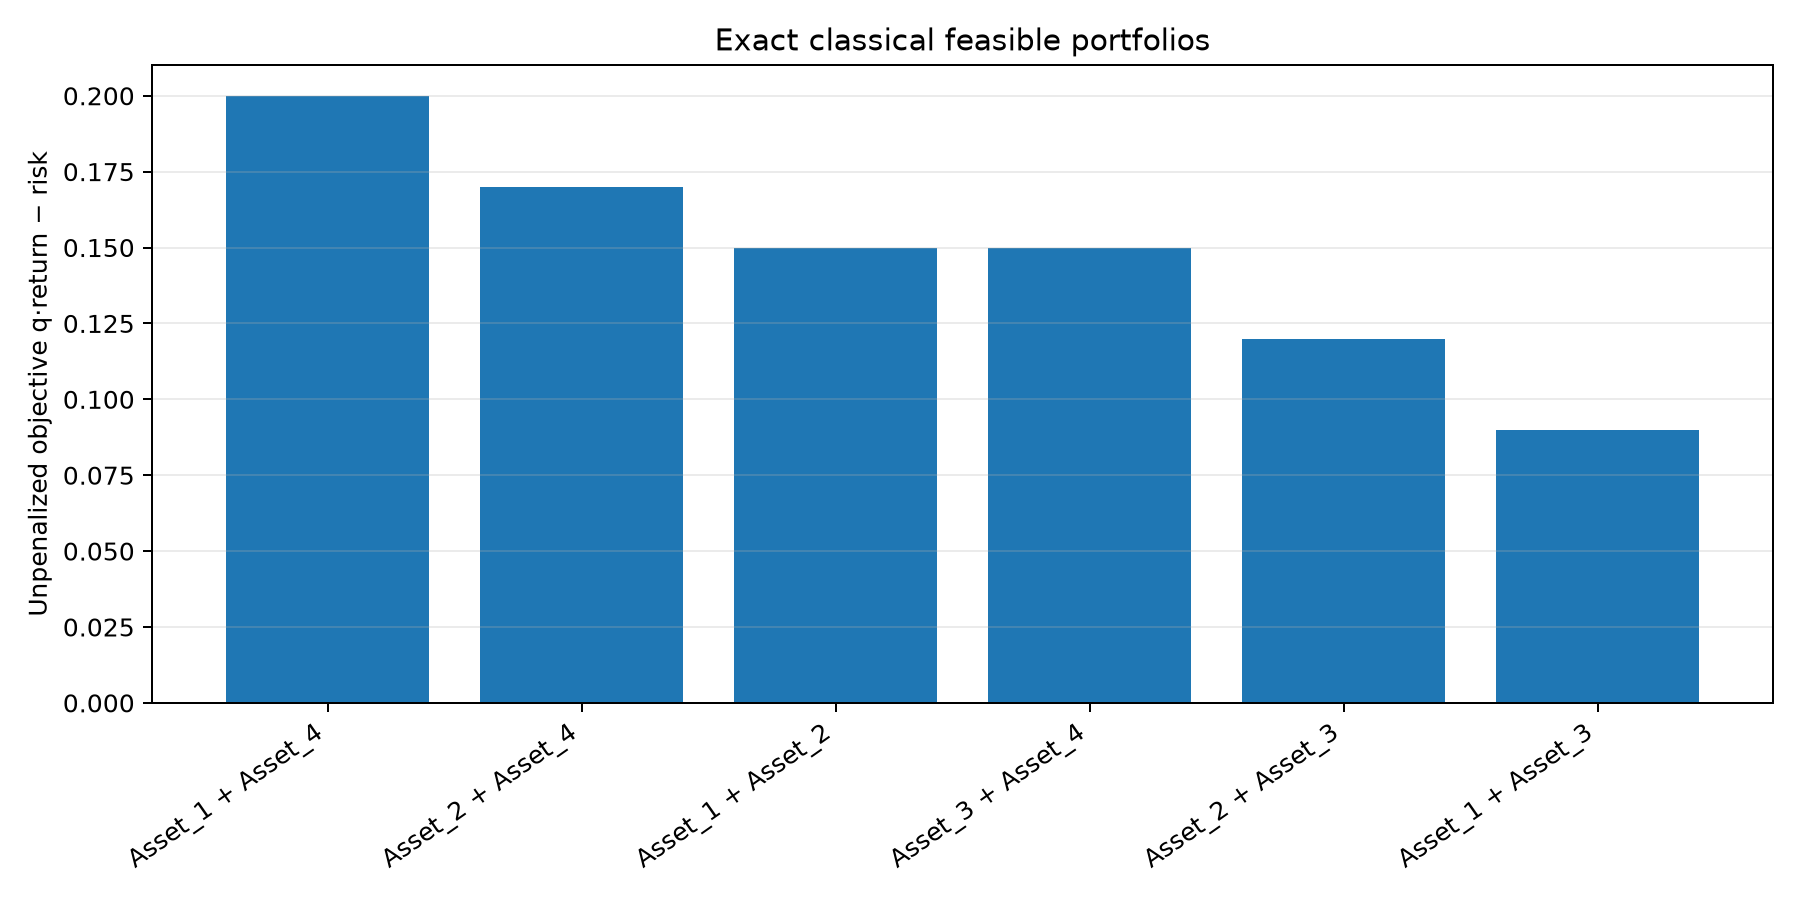

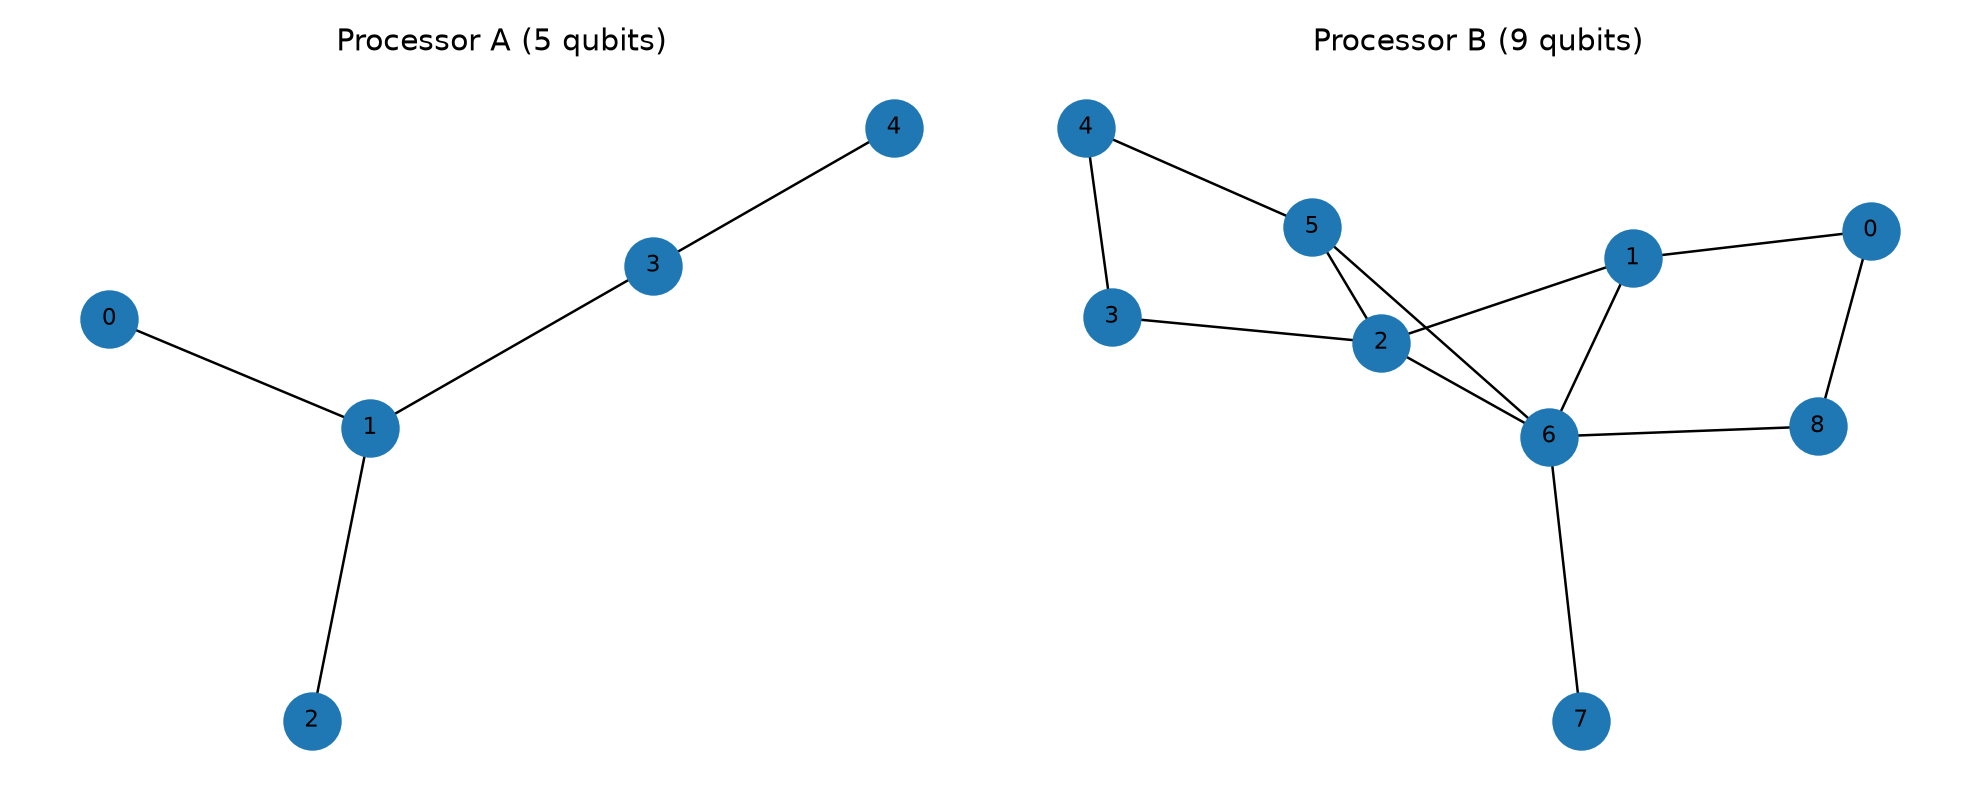

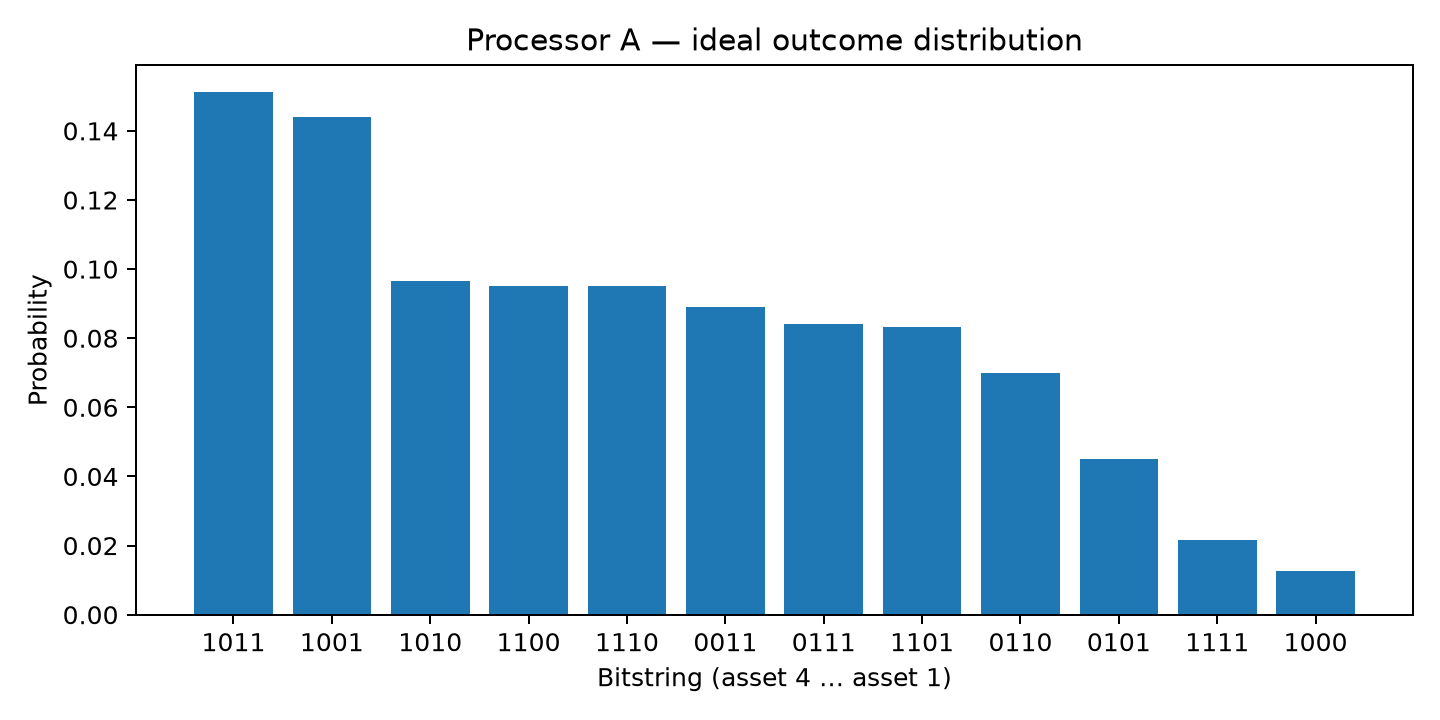

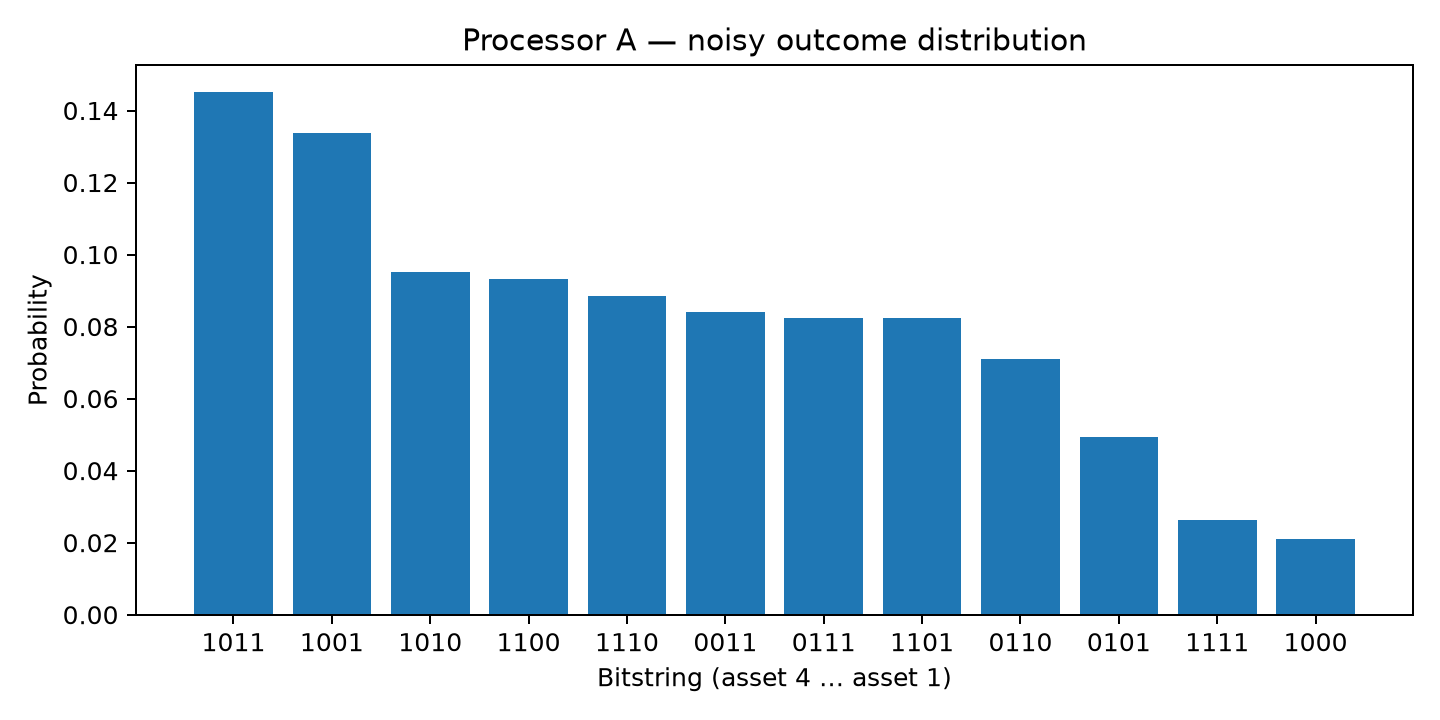

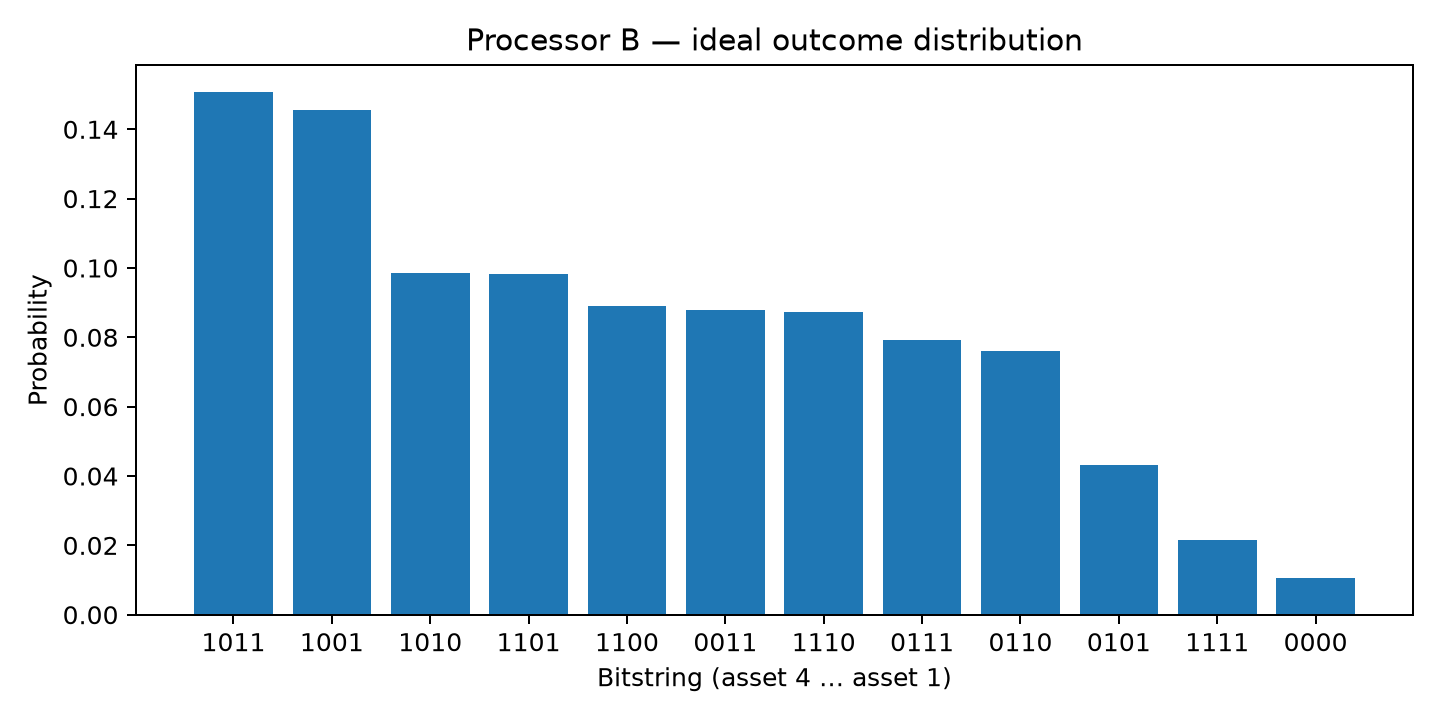

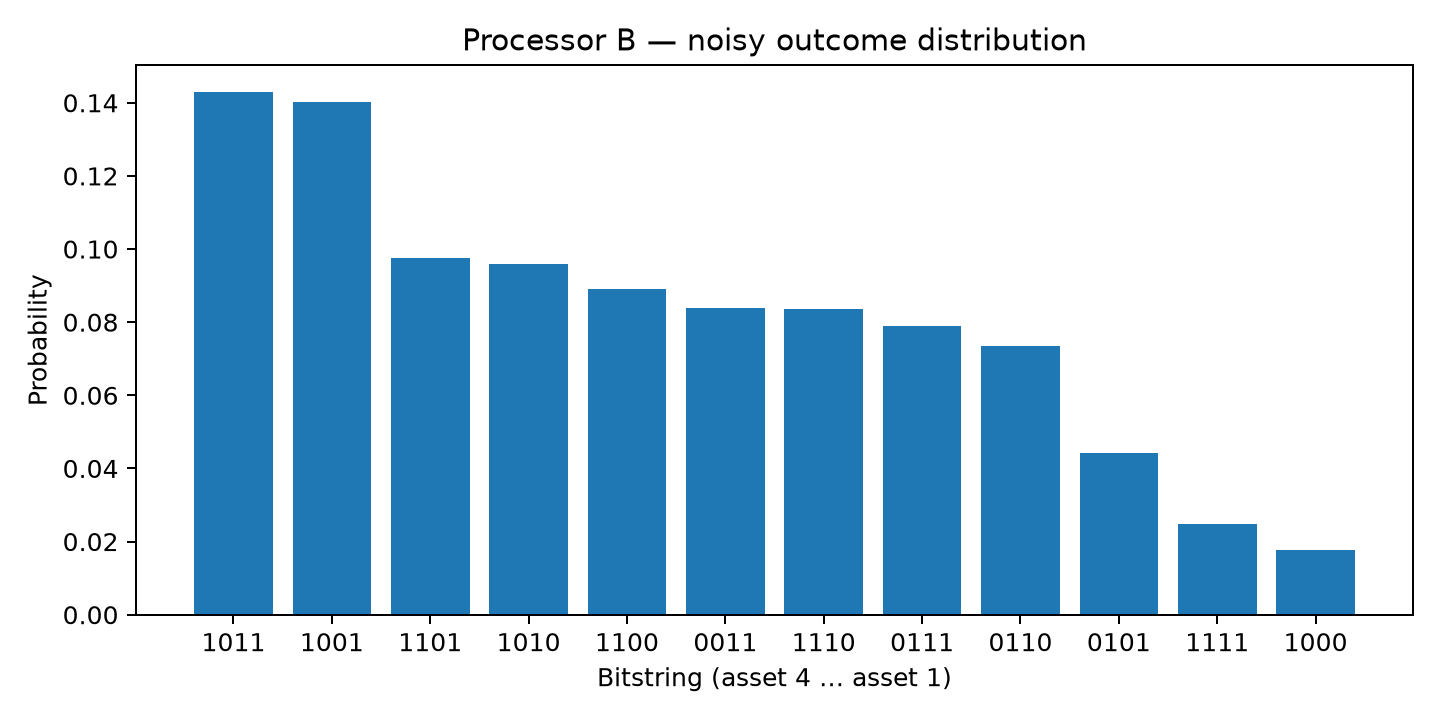

# QFF 2026 Phase 1 — PS-O2 Portfolio Optimization

## Benchmark provenance

- Inputs: QFF Phase 1 Master Guide, page 4.
- Returns μ: `[0.12, 0.18, 0.1, 0.22]`
- Risk matrix minimum eigenvalue: `0.02363584`
- q: `1.0` — participant-selected because the Master Guide's PS-O2 section does not prescribe a numeric value.
- Cardinality: exactly 2 assets.
- Penalty A: `0.02` — provisional participant-selected assumption pending organizer confirmation; the Master Guide PS-O2 entry does not specify A.
- Formulation: minimize `x.T @ Sigma @ x - q * mu.T @ x + A * (sum(x)-2)^2`.
- Reported economic objective: `q * mu.T @ x - x.T @ Sigma @ x`, only on feasible portfolios.

## Exact classical reference

- Optimal portfolio: Asset_1, Asset_4
- Bitstring (asset 4 … asset 1): `1001`
- Best feasible unpenalized objective: `0.2000000000`

## Controlled Processor A/B results

| Processor | Mode | Qubits | Depth | CX | SWAP diagnostic | Valid probability | Optimal probability | Mean utility (all samples) | Mean utility (valid only) | Best sampled valid objective | Best-sample ratio | Gap |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Processor A | ideal | 5 | 43 | 18 | 2 | 0.5396 | 0.1440 | 0.16359619 | 0.15805430 | 0.20000000 | 1.000000 | 0.00000000 |
| Processor A | noisy | 5 | 43 | 18 | 2 | 0.5266 | 0.1338 | 0.16114746 | 0.15665276 | 0.20000000 | 1.000000 | 0.00000000 |
| Processor B | ideal | 9 | 35 | 15 | 1 | 0.5403 | 0.1455 | 0.16387695 | 0.15810212 | 0.20000000 | 1.000000 | 0.00000000 |
| Processor B | noisy | 9 | 35 | 15 | 1 | 0.5266 | 0.1401 | 0.16186768 | 0.15772833 | 0.20000000 | 1.000000 | 0.00000000 |

## Compilation protocol

- QAOA p=1; same logical circuit and optimized angles for both processors.
- Basis gates `{rz, sx, x, cx}`; optimization level 1; SABRE layout/routing; transpiler seed 42; 4096 shots.
- Noise model: one-qubit depolarizing 0.001; CX depolarizing 0.005. The guide only gives a 1% readout error rate, not a confusion matrix; this implementation models it as symmetric 1% bit-flip and records that assumption. Ideal and noisy runs are reported separately.
- SWAP count comes from a separate diagnostic transpilation with SWAP retained; it is not the native-basis circuit's literal SWAP count.

## Interpretation and limitations

- Four assets yield only 16 bitstrings and can be solved exactly classically; no quantum advantage is claimed.
- The best-sampled objective ratio equals 1 when at least one sample reaches the exact optimum; interpret it alongside optimal-portfolio probability, not as an average-quality or success-probability metric.
- The numeric q is not specified in the Master Guide and was selected provisionally for this run; obtain organizer confirmation before treating it as official.
- Penalty A is a provisional participant-selected implementation choice; obtain organizer confirmation before treating it as official.
- Decision variables are interpreted as binary asset-selection indicators; confirm this interpretation if continuous weights were intended.
- Coupling graphs are reference architectures. The included A/B runs use the documented reference edges; any participant-designed topology must be reported separately.
- The synthetic noise results are Aer simulation measurements, not hardware measurements.
- Generative AI assisted code drafting/review and documentation organization; the participant remains responsible for checking every assumption and result, subject to the event AI-use policy.

## Reproducibility

Run every code cell in `main.ipynb` from the repository root after setting `Q` in the configuration cell. Tables are regenerated under `results/tables/`, figures under `results/figures/`, and the report at `report.md`.


## Supplementary experiment: topology, robustness, and parameter sensitivity

These are supplementary participant experiments. The four reference A/B × ideal/noisy rows above remain the required baseline and are not replaced by these results.

### Topology structure and compiled-resource comparison

| Processor | Topology | Mode | Edges | Diameter | Avg. shortest path | Depth | CX | SWAP diagnostic | Valid probability | Optimal probability |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Processor A | Master Guide reference | ideal | 4 | 3 | 1.800 | 43 | 18 | 2 | 0.5396 | 0.1440 |
| Processor A | Master Guide reference | noisy | 4 | 3 | 1.800 | 43 | 18 | 2 | 0.5266 | 0.1338 |
| Processor B | Master Guide reference | ideal | 12 | 4 | 1.944 | 35 | 15 | 1 | 0.5403 | 0.1455 |
| Processor B | Master Guide reference | noisy | 12 | 4 | 1.944 | 35 | 15 | 1 | 0.5266 | 0.1401 |
| Processor A | Alternative: alternative linear chain | ideal | 4 | 4 | 2.000 | 38 | 21 | 3 | 0.5476 | 0.1450 |
| Processor A | Alternative: alternative linear chain | noisy | 4 | 4 | 2.000 | 38 | 21 | 3 | 0.5327 | 0.1362 |
| Processor B | Alternative: alternative balanced ring with chords | ideal | 12 | 3 | 1.861 | 43 | 18 | 2 | 0.5422 | 0.1382 |
| Processor B | Alternative: alternative balanced ring with chords | noisy | 12 | 3 | 1.861 | 43 | 18 | 2 | 0.5234 | 0.1296 |

![Reference and alternative coupling graphs](results/figures/topology_alternatives.png)

### Noisy-seed robustness

The following intervals summarize ten simulator seeds (7, 21, 42, 84, 126, 168, 210, 252, 294, 336), with 4096 shots per run. These are exploratory Monte Carlo intervals for the simulator, not hardware uncertainty estimates.

| Processor | Topology | Mean valid probability | SD across seeds | 95% t interval (valid probability) | Mean optimal probability | SD across seeds |
|---|---|---:|---:|---:|---:|---:|
| Processor A | Master Guide reference | 0.5218 | 0.0081 | [0.5160, 0.5276] | 0.1299 | 0.0046 |
| Processor A | Alternative: alternative linear chain | 0.5180 | 0.0077 | [0.5125, 0.5236] | 0.1306 | 0.0043 |
| Processor B | Master Guide reference | 0.5207 | 0.0068 | [0.5158, 0.5256] | 0.1329 | 0.0042 |
| Processor B | Alternative: alternative balanced ring with chords | 0.5193 | 0.0068 | [0.5144, 0.5241] | 0.1311 | 0.0036 |

### Exact sensitivity to the unspecified q

The Master Guide does not prescribe q. The grid below is a participant-created sensitivity analysis, not an attempt to infer the official value.

| q | Exact optimal feasible portfolio(s) | Best feasible utility |
|---:|---|---:|
| 0.25 | Asset_1 + Asset_4 | -0.055000 |
| 0.50 | Asset_1 + Asset_4 | 0.030000 |
| 0.75 | Asset_1 + Asset_4 | 0.115000 |
| 1.00 | Asset_1 + Asset_4 | 0.200000 |
| 1.25 | Asset_1 + Asset_4 | 0.285000 |
| 1.50 | Asset_1 + Asset_4; Asset_2 + Asset_4 | 0.370000 |
| 2.00 | Asset_2 + Asset_4 | 0.570000 |

![Portfolio objective sensitivity to q](results/figures/q_sensitivity.png)

### Exact sensitivity to the cardinality penalty A

For the current provisional q=1, exact enumeration gives a strict-feasibility threshold A > 0.01 for this four-asset instance under the implemented squared-cardinality penalty. This threshold is instance- and q-specific; it is not an organizer-prescribed value for A.

| A | One optimal bitstring | Selected count | Feasible? | Infeasible optimum tie? |
|---:|---|---:|---|---|
| 0.001 | 1011 | 3 | no / tie | yes |
| 0.005 | 1011 | 3 | no / tie | yes |
| 0.01 | 1001 | 2 | no / tie | yes |
| 0.02 | 1001 | 2 | yes | no |
| 0.05 | 1001 | 2 | yes | no |
| 0.1 | 1001 | 2 | yes | no |
| 0.5 | 1001 | 2 | yes | no |
| 1 | 1001 | 2 | yes | no |
| 5 | 1001 | 2 | yes | no |
| 20 | 1001 | 2 | yes | no |

![Penalty sensitivity](results/figures/penalty_sensitivity.png)

### Reproducibility and limitations

- All topology alternatives keep the A/B qubit budget and edge count fixed and use the same logical p=1 QAOA parameters as the reference baseline.
- The reference `processors/processor_A.json` and `processors/processor_B.json` files are unchanged. Alternative edges are explicitly exported in `results/tables/topology_experiment_metadata.json`.
- Ten seeds are a useful robustness check but are not a claim of hardware-level confidence or generalization to other circuits.
- q and A still require organizer clarification; values used here are provisional participant choices.
- These are simulator results for a 4-variable, 16-state problem. No quantum-advantage claim is made.
- Generative AI assisted with code drafting/review and documentation organization; the participant is responsible for verifying the final code and claims, subject to the event policy.


In [5]:
from IPython.display import display, Image, Markdown
with (ROOT / "results/tables/processor_comparison.csv").open(newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        print(row)
for image_name in [
    "classical_portfolio_objectives.png",
    "processor_topologies.png",
    "qaoa_distribution_processor_a_ideal.png",
    "qaoa_distribution_processor_a_noisy.png",
    "qaoa_distribution_processor_b_ideal.png",
    "qaoa_distribution_processor_b_noisy.png",
]:
    image_path = ROOT / "results/figures" / image_name
    if image_path.exists():
        display(Image(filename=str(image_path)))
display(Markdown((ROOT / "report.md").read_text(encoding="utf-8")))
